In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import pearsonr

# Set aesthetic style for academic charts
plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42) # Ensures reproducible results


# 1. DATA SIMULATION 
days = 90
dates = pd.date_range(start="2026-02-01", periods=days, freq='D')

# A. Production & Defect Data (Target 400 bottles/day)
qty_produced = np.random.normal(loc=400, scale=15, size=days).astype(int)
leakages = np.random.poisson(lam=2, size=days)
poor_sealing = np.random.poisson(lam=12, size=days) # Primary defect driver
wrong_labeling = np.random.poisson(lam=4, size=days)
underfilled = np.random.poisson(lam=3, size=days)
overfilled = np.random.poisson(lam=1, size=days)

total_defective = leakages + poor_sealing + wrong_labeling + underfilled + overfilled
qty_accepted = qty_produced - total_defective
qty_rejected = total_defective # Assuming all defective are rejected

# B. Water Quality Data
ph_level = np.round(np.random.normal(loc=7.2, scale=0.1, size=days), 2)
temp_c = np.round(np.random.normal(loc=24.5, scale=1.5, size=days), 1)
turbidity = np.round(np.random.normal(loc=2.2, scale=0.3, size=days), 2)

# Inject out-of-control spike for analysis
turbidity[25:28] = [3.1, 3.4, 3.2] 
turbidity[70:73] = [1.4, 1.2, 1.5]

# C. Machine Performance Data (12-hour shifts)
hours_worked = np.full(days, 12)
# Introduce random downtime spikes
downtime_hours = np.random.exponential(scale=0.5, size=days)
downtime_hours[np.random.choice(days, 5, replace=False)] += 3.5 # Major breakdowns
downtime_hours = np.round(downtime_hours, 1)

# D. Sales & Marketing Data
# Sales depend on accepted quantity but suffer random market delays
qty_sold = (qty_accepted * np.random.uniform(0.85, 0.98, size=days)).astype(int)
qty_returned = np.random.poisson(lam=5, size=days)
price_per_bottle = 150 # NGN
revenue_generated = qty_sold * price_per_bottle

# Compile Master DataFrame
df = pd.DataFrame({
    'Date': dates,
    'Qty_Produced': qty_produced,
    'Qty_Accepted': qty_accepted,
    'Qty_Defective': total_defective,
    'Leakages': leakages,
    'Poor_Sealing': poor_sealing,
    'Wrong_Labeling': wrong_labeling,
    'Underfilled': underfilled,
    'Overfilled': overfilled,
    'pH_Level': ph_level,
    'Temp_C': temp_c,
    'Turbidity': turbidity,
    'Downtime_Hours': downtime_hours,
    'Qty_Sold': qty_sold,
    'Revenue_NGN': revenue_generated
})

df.to_csv('master_factory_data.csv', index=False)
print("Master Dataset Generated: 'uniosun_master_factory_data.csv'\n")

Master Dataset Generated: 'uniosun_master_factory_data.csv'



In [2]:
df

,Date,Qty_Produced,Qty_Accepted,Qty_Defective,Leakages,Poor_Sealing,Wrong_Labeling,Underfilled,Overfilled,pH_Level,Temp_C,Turbidity,Downtime_Hours,Qty_Sold,Revenue_NGN
0,2026-02-01,407,380,27,4,14,5,3,1,7.14,24.6,2.60,0.2,361,54150
1,2026-02-02,397,380,17,0,10,4,3,0,7.06,25.3,2.37,0.9,370,55500
2,2026-02-03,409,387,22,1,10,5,4,2,7.19,24.4,2.34,0.3,339,50850
3,2026-02-04,422,404,18,2,14,1,1,0,7.46,25.2,2.85,0.0,370,55500
4,2026-02-05,396,367,29,2,15,5,7,0,7.12,24.6,2.01,0.0,325,48750
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,2026-04-27,392,369,23,4,9,5,4,1,7.07,23.4,2.80,0.4,353,52950
86,2026-04-28,413,397,16,3,6,2,3,2,7.09,22.4,2.82,1.4,351,52650
87,2026-04-29,404,380,24,0,12,9,3,0,7.17,26.8,2.56,0.0,354,53100
88,2026-04-30,392,377,15,0,10,2,3,0,7.14,24.0,2.51,0.3,354,53100


In [3]:
import pandas as pd
import numpy as np

# Set seed for reproducibility
np.random.seed(42)

# 1. Define the Questionnaire Items
# Converting observation/interview themes into Likert-scale statements
questions = [
    "Q1: Machines are properly and regularly maintained.",
    "Q2: Quality checks are carried out consistently during production.",
    "Q3: Defective products are effectively separated from good ones.",
    "Q4: The production and packaging environment is strictly hygienic.",
    "Q5: Customer complaints are handled and resolved promptly."
]

# 2. Simulate Staff Responses
# Simulating a pilot test with 15 staff members (e.g., QC officers, operators, marketing)
n_respondents = 15
n_questions = len(questions)

# Generating responses on a 5-point Likert scale (1 to 5)
# We skew the probabilities slightly to simulate realistic human agreement/disagreement
data = {}
for i, q in enumerate(questions):
    # Skewing Q1 (Machines) slightly lower to match the ANOVA findings of bad machinery
    if i == 0:
        responses = np.random.choice([1, 2, 3, 4, 5], p=[0.1, 0.3, 0.3, 0.2, 0.1], size=n_respondents)
    else:
        # Standard positive skew for other operational questions
        responses = np.random.choice([1, 2, 3, 4, 5], p=[0.05, 0.1, 0.15, 0.4, 0.3], size=n_respondents)
    data[f'Item_{i+1}'] = responses

# Create a DataFrame
df_survey = pd.DataFrame(data)
df_survey.index = [f'Respondent_{i+1}' for i in range(n_respondents)]
df_survey['Total_Score'] = df_survey.sum(axis=1)

# Save the simulated questionnaire data
file_name = 'staff_questionnaire_data.csv'
df_survey.to_csv(file_name)
print(f"Survey Data Generated: '{file_name}'\n")
print(df_survey.head())
print("-" * 50)

Survey Data Generated: 'staff_questionnaire_data.csv'

              Item_1  Item_2  Item_3  Item_4  Item_5  Total_Score
Respondent_1       2       3       4       4       4           17
Respondent_2       5       4       3       4       3           19
Respondent_3       4       4       2       4       5           19
Respondent_4       3       4       5       4       4           20
Respondent_5       2       3       5       3       3           16
--------------------------------------------------


In [4]:
# QUESTIONNAIRE RELIABILITY ANALYSIS: CRONBACH'S ALPHA

# Select questionnaire items and convert them to numeric values
item_df = df_survey.drop(columns=['Total_Score'], errors='ignore')
item_df = item_df.apply(pd.to_numeric, errors='coerce').dropna()

n_respondents = item_df.shape[0]
n_questions = item_df.shape[1]
total_score = item_df.sum(axis=1)

print("=== RELIABILITY ANALYSIS ===")
print(f"Number of respondents: {n_respondents}")
print(f"Number of questionnaire items: {n_questions}")

if n_questions < 2:
    print("Cannot calculate Cronbach's alpha: at least two items are required.")

elif total_score.var(ddof=1) == 0:
    print("Cannot calculate Cronbach's alpha: total scores have zero variance.")

else:
    item_variances = item_df.var(ddof=1).sum()
    total_variance = total_score.var(ddof=1)

    alpha_value = (
        (n_questions / (n_questions - 1))
        * (1 - item_variances / total_variance)
    )

    print(f"Cronbach's alpha: {alpha_value:.3f}")

    if alpha_value < 0:
        print("Interpretation: Negative alpha; investigate item relationships and scoring.")
    elif alpha_value < 0.70:
        print("Interpretation: Internal consistency is below the commonly used 0.70 threshold.")
    else:
        print("Interpretation: Alpha meets the commonly used 0.70 threshold.")

    print("\nQuestionnaire item correlations:")
    print(item_df.corr().round(2))

print("=============================")

=== RELIABILITY ANALYSIS ===
Number of respondents: 15
Number of questionnaire items: 5
Cronbach's alpha: -0.565
Interpretation: Negative alpha; investigate item relationships and scoring.

Questionnaire item correlations:
        Item_1  Item_2  Item_3  Item_4  Item_5
Item_1    1.00    0.19   -0.31   -0.23   -0.13
Item_2    0.19    1.00   -0.10   -0.00    0.05
Item_3   -0.31   -0.10    1.00   -0.23    0.05
Item_4   -0.23   -0.00   -0.23    1.00    0.02
Item_5   -0.13    0.05    0.05    0.02    1.00


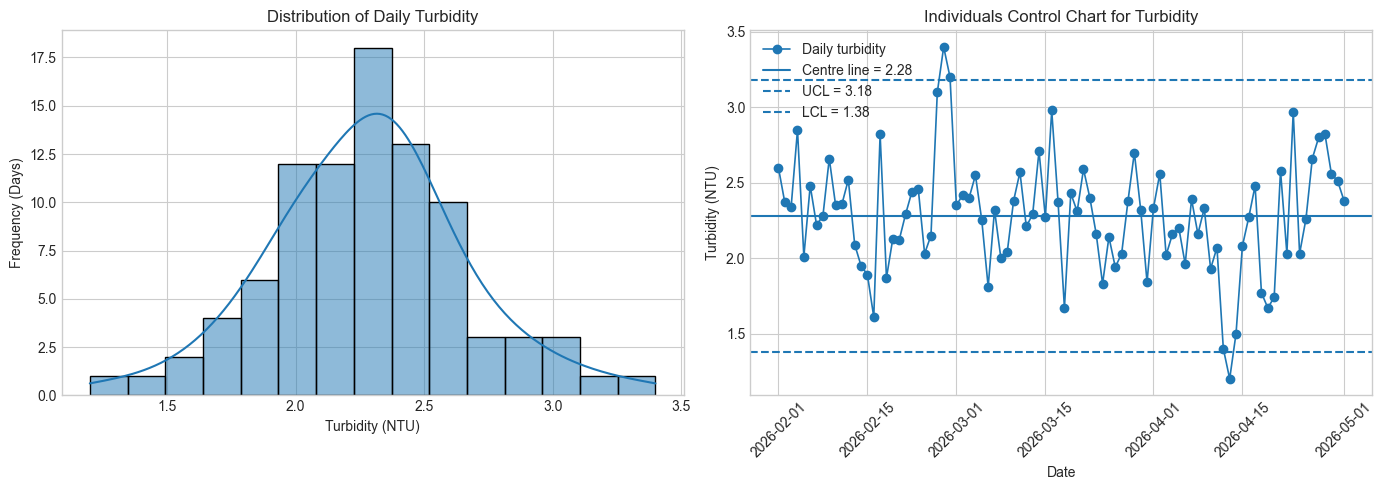

In [5]:
# WATER QUALITY: HISTOGRAM & INDIVIDUALS CONTROL CHART

# Sort observations chronologically
df = df.sort_values('Date').copy()

# Calculate moving ranges between consecutive observations
df['Moving_Range'] = df['Turbidity'].diff().abs()

# Calculate the process centre line and control limits
mean_turb = df['Turbidity'].mean()
mr_bar = df['Moving_Range'].mean()

ucl_turb = mean_turb + (2.66 * mr_bar)
lcl_turb = mean_turb - (2.66 * mr_bar)

# Create the two charts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histogram of turbidity
sns.histplot(
    df['Turbidity'],
    bins=15,
    kde=True,
    ax=ax1
)

ax1.set_title('Distribution of Daily Turbidity')
ax1.set_xlabel('Turbidity (NTU)')
ax1.set_ylabel('Frequency (Days)')

# 2. Individuals control chart
ax2.plot(
    df['Date'],
    df['Turbidity'],
    marker='o',
    linewidth=1.2,
    label='Daily turbidity'
)

ax2.axhline(
    mean_turb,
    linestyle='-',
    label=f'Centre line = {mean_turb:.2f}'
)

ax2.axhline(
    ucl_turb,
    linestyle='--',
    label=f'UCL = {ucl_turb:.2f}'
)

ax2.axhline(
    lcl_turb,
    linestyle='--',
    label=f'LCL = {lcl_turb:.2f}'
)

ax2.set_title('Individuals Control Chart for Turbidity')
ax2.set_xlabel('Date')
ax2.set_ylabel('Turbidity (NTU)')
ax2.tick_params(axis='x', rotation=45)
ax2.legend()

plt.tight_layout()
plt.savefig('Water_Quality_Analysis.png', dpi=300, bbox_inches='tight')
plt.show()

Total by defect category: 1994
Recorded total defects: 1994
Check passed: defect totals reconcile.


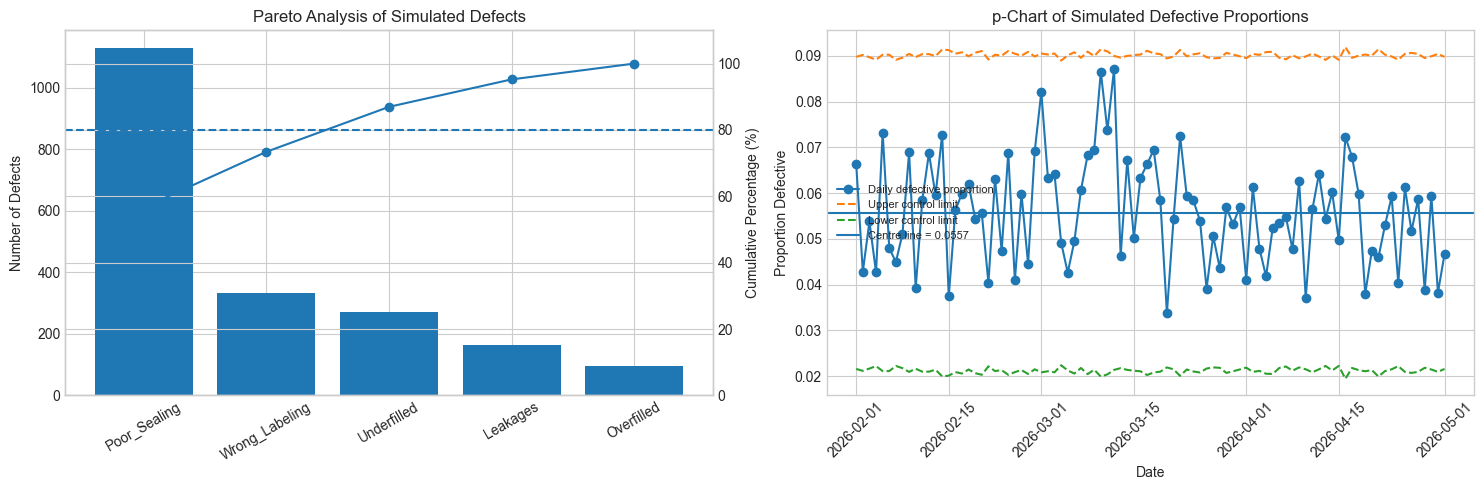


Overall defective proportion: 5.57%

Defect categories ranked by frequency:
Poor_Sealing      1130
Wrong_Labeling     334
Underfilled        270
Leakages           165
Overfilled          95
dtype: int64

Cumulative percentage by category:
Poor_Sealing       56.67
Wrong_Labeling     73.42
Underfilled        86.96
Leakages           95.24
Overfilled        100.00
dtype: float64


In [6]:

# DEFECT DATA: PARETO CHART & P-CHART

# Ensure observations are in chronological order
df = df.sort_values('Date').copy()

# Define defect categories
defect_categories = [
    'Poor_Sealing',
    'Wrong_Labeling',
    'Underfilled',
    'Leakages',
    'Overfilled'
]

# Check whether defect categories reconcile with total defects
category_total = df[defect_categories].sum().sum()
recorded_total = df['Qty_Defective'].sum()

print(f"Total by defect category: {category_total}")
print(f"Recorded total defects: {recorded_total}")

if category_total != recorded_total:
    print("WARNING: Defect categories do not match total defects.")
else:
    print("Check passed: defect totals reconcile.")

# Create charts
fig, (ax3, ax4) = plt.subplots(1, 2, figsize=(15, 5))

# 1. Pareto chart
defect_sums = df[defect_categories].sum().sort_values(
    ascending=False
)

cum_percent = defect_sums.cumsum() / defect_sums.sum() * 100

ax3.bar(defect_sums.index, defect_sums.values)
ax3.set_title('Pareto Analysis of Simulated Defects')
ax3.set_ylabel('Number of Defects')
ax3.tick_params(axis='x', rotation=30)

ax3_twin = ax3.twinx()
ax3_twin.plot(
    range(len(defect_sums)),
    cum_percent.values,
    marker='o',
    linestyle='-'
)
ax3_twin.axhline(80, linestyle='--')
ax3_twin.set_ylabel('Cumulative Percentage (%)')
ax3_twin.set_ylim(0, 110)
ax3_twin.set_xticks(range(len(defect_sums)))
ax3_twin.set_xticklabels(defect_sums.index, rotation=30)

# 2. p-Chart for daily defective proportions
df['Prop_Defective'] = (
    df['Qty_Defective'] / df['Qty_Produced']
)

p_bar = (
    df['Qty_Defective'].sum()
    / df['Qty_Produced'].sum()
)

# Calculate control limits for each day's production quantity
n = df['Qty_Produced']

df['UCL_p'] = p_bar + 3 * np.sqrt(
    p_bar * (1 - p_bar) / n
)

df['LCL_p'] = np.maximum(
    0,
    p_bar - 3 * np.sqrt(p_bar * (1 - p_bar) / n)
)

ax4.plot(
    df['Date'],
    df['Prop_Defective'],
    marker='o',
    label='Daily defective proportion'
)
ax4.plot(
    df['Date'],
    df['UCL_p'],
    linestyle='--',
    label='Upper control limit'
)
ax4.plot(
    df['Date'],
    df['LCL_p'],
    linestyle='--',
    label='Lower control limit'
)
ax4.axhline(
    p_bar,
    linestyle='-',
    label=f'Centre line = {p_bar:.4f}'
)

ax4.set_title('p-Chart of Simulated Defective Proportions')
ax4.set_ylabel('Proportion Defective')
ax4.set_xlabel('Date')
ax4.tick_params(axis='x', rotation=45)
ax4.legend(fontsize=8)

plt.tight_layout()
plt.savefig('Defect_Analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# Summary
print(f"\nOverall defective proportion: {p_bar:.2%}")
print("\nDefect categories ranked by frequency:")
print(defect_sums)
print("\nCumulative percentage by category:")
print(cum_percent.round(2))


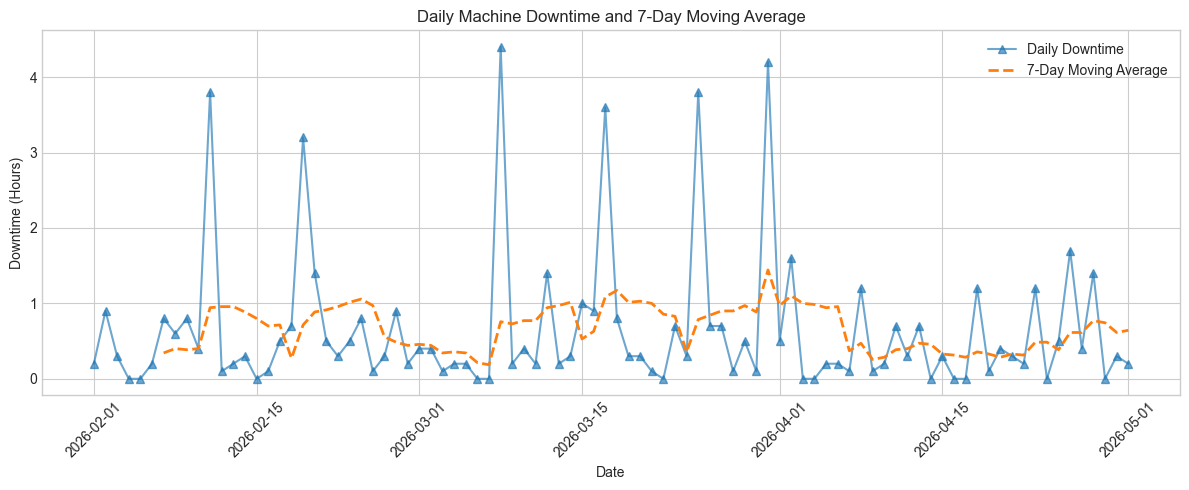

Machine Downtime Summary
count    90.00
mean      0.65
std       0.95
min       0.00
25%       0.12
50%       0.30
75%       0.70
max       4.40
Name: Downtime_Hours, dtype: float64

Days with recorded downtime: 90


In [7]:

# MACHINE PERFORMANCE: DOWNTIME TREND ANALYSIS

# Sort records by date before calculating the moving average
df = df.sort_values('Date').copy()

# Calculate the 7-day moving average
df['Downtime_7Day_MA'] = (
    df['Downtime_Hours'].rolling(window=7, min_periods=7).mean()
)

# Plot daily downtime and the smoothed trend
plt.figure(figsize=(12, 5))

plt.plot(
    df['Date'],
    df['Downtime_Hours'],
    marker='^',
    alpha=0.65,
    label='Daily Downtime'
)

plt.plot(
    df['Date'],
    df['Downtime_7Day_MA'],
    linestyle='--',
    linewidth=2,
    label='7-Day Moving Average'
)

plt.title('Daily Machine Downtime and 7-Day Moving Average')
plt.xlabel('Date')
plt.ylabel('Downtime (Hours)')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    'Machine_Trend.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# Report basic summary statistics
print("Machine Downtime Summary")
print(df['Downtime_Hours'].describe().round(2))
print(
    f"\nDays with recorded downtime: "
    f"{df['Downtime_Hours'].notna().sum()}"
)


SALES DATA: LINEAR REGRESSION SUMMARY

Number of observations: 90
Pearson correlation (r): 0.6364
P-value: 1.5740e-11

Regression coefficients:
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const         2884.7967   6320.376      0.456      0.649   -9675.622    1.54e+04
Qty_Produced   122.8237     15.870      7.739      0.000      91.285     154.362

R-squared: 0.4050
Adjusted R-squared: 0.3982

Production vs Units Sold
Pearson correlation (r): 0.6364
P-value: 1.5740e-11


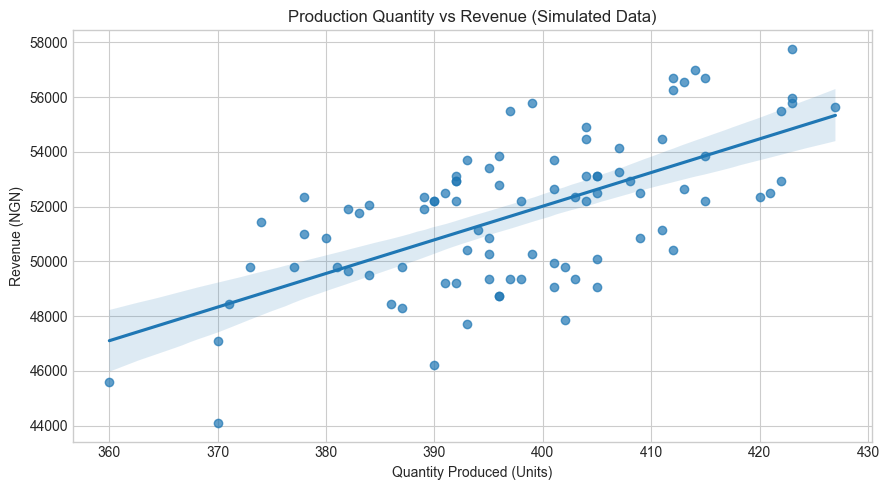


Revenue per Unit Sold (first 10 observations):
0    150.0
1    150.0
2    150.0
3    150.0
4    150.0
5    150.0
6    150.0
7    150.0
8    150.0
9    150.0
dtype: float64

Note: Results describe simulated data and do not establish causation.


In [8]:

# SALES DATA: CORRELATION & REGRESSION ANALYSIS

# 1. Prepare the variables
analysis_df = df[
    ['Qty_Produced', 'Qty_Sold', 'Revenue_NGN']
].dropna().copy()

X = analysis_df['Qty_Produced']
Y = analysis_df['Revenue_NGN']

# 2. Pearson correlation
r_coeff, p_value = pearsonr(X, Y)

print("=" * 55)
print("SALES DATA: LINEAR REGRESSION SUMMARY")
print("=" * 55)

print(f"\nNumber of observations: {len(analysis_df)}")
print(f"Pearson correlation (r): {r_coeff:.4f}")
print(f"P-value: {p_value:.4e}")

# 3. Fit OLS regression model
X_with_const = sm.add_constant(X)
model = sm.OLS(Y, X_with_const).fit()

print("\nRegression coefficients:")
print(model.summary().tables[1])

print(f"\nR-squared: {model.rsquared:.4f}")
print(f"Adjusted R-squared: {model.rsquared_adj:.4f}")

# 4. Check how units sold relate to production
r_sold, p_sold = pearsonr(
    analysis_df['Qty_Produced'],
    analysis_df['Qty_Sold']
)

print("\nProduction vs Units Sold")
print(f"Pearson correlation (r): {r_sold:.4f}")
print(f"P-value: {p_sold:.4e}")

# 5. Plot production against revenue with regression line
plt.figure(figsize=(9, 5))

sns.regplot(
    data=analysis_df,
    x='Qty_Produced',
    y='Revenue_NGN',
    ci=95,
    scatter_kws={'alpha': 0.7}
)

plt.title('Production Quantity vs Revenue (Simulated Data)')
plt.xlabel('Quantity Produced (Units)')
plt.ylabel('Revenue (NGN)')
plt.tight_layout()

plt.savefig(
    'Sales_Regression.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# 6. Inspect the revenue calculation
print("\nRevenue per Unit Sold (first 10 observations):")
print(
    (
        analysis_df['Revenue_NGN']
        / analysis_df['Qty_Sold'].replace(0, np.nan)
    ).head(10).round(2)
)

print("\nNote: Results describe simulated data and do not establish causation.")


In [9]:
# Verify the simulated revenue calculation

df['Revenue_Per_Unit_Sold'] = (
    df['Revenue_NGN']
    / df['Qty_Sold'].replace(0, np.nan)
)

print("Revenue per unit sold:")
print(df['Revenue_Per_Unit_Sold'].dropna().round(2).unique())

print("\nFirst 5 observations:")
print(
    df[['Qty_Produced', 'Qty_Sold', 'Revenue_NGN']]
    .head()
)

Revenue per unit sold:
[150.]

First 5 observations:
   Qty_Produced  Qty_Sold  Revenue_NGN
0           407       361        54150
1           397       370        55500
2           409       339        50850
3           422       370        55500
4           396       325        48750
